# HW5 walkthrough: Ames Housing quality audit

This notebook runs the same steps as `make all`, one part at a time, so the output of each
step can be seen. It is a study aid. The graded pipeline is the scripts in `src/` run by
`make all`; this notebook imports from those scripts and does not replace them.

Run it from the repo folder (the one that holds `src/` and `Makefile`).

In [1]:
import hashlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "src")          # so the notebook can import the scripts in src/

RAW = "data/raw/AmesHousing.txt"
CLEAN = "data/processed/ames_clean.csv"
pd.set_option("display.max_colwidth", 90)

## Part 1: provenance
Download the raw file once (skipped if it already exists), then check its shape and fingerprint.

In [2]:
!python src/download.py data/raw/AmesHousing.txt

data/raw/AmesHousing.txt already exists, not downloading again.


In [3]:
raw_default = pd.read_csv(RAW, sep="\t")
print("shape on arrival:", raw_default.shape)
print("sha256:", hashlib.sha256(open(RAW, "rb").read()).hexdigest())
raw_default.iloc[:3, :8]

shape on arrival: (2930, 82)
sha256: 6cfe6cb525ba437de428653a1040e2aed7d696640bf75203786a6d7a0e67cfcc


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley
0,1,526301100,20,RL,141.0,31770,Pave,NaN
1,2,526350040,20,RH,80.0,11622,Pave,NaN
2,3,526351010,20,RL,81.0,14267,Pave,NaN


## Part 2: validation on the raw file
The rules live in `src/validate.py` as plain data: a schema, ranges and allowed values.

In [4]:
import validate as v

print("schema columns :", len(v.TEXT_COLS), "text +", len(v.NUMERIC_COLS), "numeric")
print("range rules    :", len(v.RANGES))
print("allowed sets   :", len(v.ALLOWED))
print()
print("examples")
print("  Yr Sold      ", v.RANGES["Yr Sold"])
print("  Garage Yr Blt", v.RANGES["Garage Yr Blt"])
print("  Bldg Type    ", sorted(v.ALLOWED["Bldg Type"]))

schema columns : 44 text + 38 numeric
range rules    : 36
allowed sets   : 44

examples
  Yr Sold       (2006, 2010)
  Garage Yr Blt (1864, 2010)
  Bldg Type     ['1Fam', '2FmCon', 'Duplx', 'TwnhsE', 'TwnhsI']


Load the raw file keeping `NA` and `None` as text, then run each check. Each one returns a list of failure messages.

In [5]:
from clean import load_raw

raw = load_raw(RAW)

for check in [v.check_schema, v.check_ranges, v.check_allowed, v.check_cross_column]:
    errors = check(raw)
    print(f"{check.__name__}: {len(errors)} failure(s)")
    for e in errors:
        print("   ", e)
    print()

check_schema: 0 failure(s)

check_ranges: 1 failure(s)
    range: Garage Yr Blt outside [1864, 2010] in 1 rows: [2207.]

check_allowed: 5 failure(s)
    allowed: MS Zoning has codes not in the dictionary: {'C (all)': 25, 'I (all)': 2, 'A (agr)': 2}
    allowed: Neighborhood has codes not in the dictionary: {'NAmes': 443}
    allowed: Bldg Type has codes not in the dictionary: {'Duplex': 109, 'Twnhs': 101, '2fmCon': 62}
    allowed: Exterior 2nd has codes not in the dictionary: {'CmentBd': 126, 'Wd Shng': 81, 'Brk Cmn': 22}
    allowed: Sale Type has codes not in the dictionary: {'WD ': 2536}

check_cross_column: 4 failure(s)
    cross: Year Remod/Add >= Year Built fails in 1 rows, Order [851]
    cross: Mas Vnr Type == None iff Mas Vnr Area == 0 fails in 10 rows, Order [364, 404, 442, 1641, 1741, 1786, 1862, 1914, 2004, 2529]
    cross: Garage Qual == NA iff Garage Type == NA fails in 1 rows, Order [1357]
    cross: Garage Cond == NA iff Garage Type == NA fails in 1 rows, Order [1357]


In [6]:
try:
    v.validate(raw)
    print("PASS")
except v.ValidationError as e:
    print("FAIL: the raw file breaks", len(str(e).splitlines()), "rules")

FAIL: the raw file breaks 10 rules


## Part 3: sentinels and structural absence
Load the file two ways and compare. The default load turns the text `NA` and `None` into NaN.

In [7]:
kept = load_raw(RAW)

rows = []
for col in kept.columns:
    n_na = (kept[col] == "NA").sum()
    n_none = (kept[col] == "None").sum()
    n_empty = kept[col].isna().sum()
    if n_na + n_none + n_empty > 0:
        rows.append({"column": col, '"NA" text': n_na, '"None" text': n_none,
                     "empty cells": n_empty,
                     "NaN with default load": raw_default[col].isna().sum()})
na_audit = pd.DataFrame(rows).set_index("column")
print("codes the default load destroys:", int(na_audit['"NA" text'].sum() + na_audit['"None" text'].sum()))
na_audit

codes the default load destroys: 15030


,"""NA"" text","""None"" text",empty cells,NaN with default load
column,,,,
Lot Frontage,0,0,490,490
Alley,2732,0,0,2732
Mas Vnr Type,0,1752,23,1775
Mas Vnr Area,0,0,23,23
Bsmt Qual,79,0,1,80
Bsmt Cond,79,0,1,80
Bsmt Exposure,79,0,4,83
BsmtFin Type 1,79,0,1,80
BsmtFin SF 1,0,0,1,1


Now apply the seven fixes in `decode_missing`. Every change is logged.

In [8]:
import clean

clean.fixes.clear()                       # so re-running this cell doesn't double the log
df = clean.decode_missing(raw)


### fixes
| problem                                           |   rows | Order (first 8)                          | action                    |
|:--------------------------------------------------|-------:|:-----------------------------------------|:--------------------------|
| Sale Type 'WD ' has a trailing space              |   2536 | [1, 2, 3, 4, 5, 6, 7, 8]                 | strip spaces              |
| MS Zoning: 'C (all)' not in dictionary            |     25 | [214, 305, 306, 307, 308, 721, 727, 728] | change to 'C'             |
| MS Zoning: 'I (all)' not in dictionary            |      2 | [946, 1611]                              | change to 'I'             |
| MS Zoning: 'A (agr)' not in dictionary            |      2 | [1554, 2904]                             | change to 'A'             |
| Neighborhood: 'NAmes' not in dictionary           |    443 | [1, 2, 3, 4, 24, 25, 26, 27]             | change to 'Names'         |
| Bldg Type: '2fmCon' not in dictionary            

## Part 4: keys, duplicates and the lookup join

In [9]:
clean.check_keys(df)


### keys
| check                                           |   result |
|:------------------------------------------------|---------:|
| Order is unique                                 |     True |
| PID is unique                                   |     True |
| exact duplicate rows                            |        0 |
| duplicate rows ignoring Order                   |        0 |
| duplicate PID                                   |        0 |
| PIDs starting with 0 (lost if read as a number) |     2929 |

lookup join: 2930 rows before, 2930 after, 0 unmatched


Save the cleaned file and validate it. This time it has to pass.

In [10]:
import os

os.makedirs("data/processed", exist_ok=True)
df.to_csv(CLEAN, index=False)

from common import load_clean

df = load_clean(CLEAN)
v.validate(df)
print("PASS", CLEAN, df.shape)

PASS data/processed/ames_clean.csv (2930, 82)


## Part 5: missingness mechanism
Split the houses into "value missing" and "value present" and compare the two groups on
columns we can see. If the gaps were completely random, the groups would look alike.

In [11]:
from missingness import compare_groups, missing_by

print("Lot Frontage:", df["Lot Frontage"].isna().sum(), "missing of", len(df))
compare_groups(df, "Lot Frontage")

Lot Frontage: 490 missing of 2930


,compared on,missing group,present group,test,p-value
0,SalePrice,"median 173,000","median 157,500",Mann-Whitney U,5.2e-06
1,Lot Area,"median 10,398","median 9,248",Mann-Whitney U,1.4e-12
2,Gr Liv Area,"median 1,488","median 1,434",Mann-Whitney U,4.8e-03
3,Year Built,"median 1,976","median 1,972",Mann-Whitney U,3.2e-01
4,Lot Config,13% (Inside) to 49% (CulDSac),overall 16.7% missing,chi-square,6.2e-35
5,Neighborhood,0% (BrDale) to 55% (ClearCr),overall 16.7% missing,chi-square,1.0e-40
6,Bldg Type,5% (2FmCon) to 17% (1Fam),overall 16.7% missing,chi-square,6.5e-03


In [12]:
missing_by(df, "Lot Frontage", "Lot Config")

,houses,missing,share missing
Lot Config,,,
CulDSac,180,88,0.489
FR3,14,4,0.286
FR2,85,20,0.235
Corner,511,104,0.204
Inside,2140,274,0.128


In [13]:
print("Mas Vnr Area:", df["Mas Vnr Area"].isna().sum(), "missing of", len(df))
compare_groups(df, "Mas Vnr Area")

Mas Vnr Area: 26 missing of 2930


,compared on,missing group,present group,test,p-value
0,SalePrice,"median 212,000","median 160,000",Mann-Whitney U,1.3e-05
1,Lot Area,"median 9,661","median 9,432",Mann-Whitney U,5.5e-01
2,Gr Liv Area,"median 1,557","median 1,440",Mann-Whitney U,3.5e-02
3,Year Built,"median 2,006","median 1,973",Mann-Whitney U,3.0e-10
4,Lot Config,1% (Inside) to 1% (FR2),overall 0.9% missing,chi-square,9.8e-01
5,Neighborhood,0% (Blmngtn) to 6% (Somerst),overall 0.9% missing,chi-square,6.4e-08
6,Bldg Type,0% (2FmCon) to 1% (1Fam),overall 0.9% missing,chi-square,6.0e-01


In [14]:
missing_by(df, "Mas Vnr Area", "Sale Condition")

,houses,missing,share missing
Sale Condition,,,
Partial,245,14,0.057
Alloca,24,1,0.042
Normal,2413,11,0.005
Abnorml,190,0,0.000
AdjLand,12,0,0.000
Family,46,0,0.000


## Part 6: imputation strategies and their cost
Three ways to fill Lot Frontage. For each: how much spread is lost, and how much the link
with Lot Area weakens.

In [15]:
from common import GroupMedianImputer, KNNFrontageImputer

before = df["Lot Frontage"]
missing = before.isna()

filled = {
    "median": before.fillna(before.median()),
    "neighborhood median": GroupMedianImputer().fit_transform(
        df[["Lot Frontage", "Neighborhood"]])["Lot Frontage"],
    "KNN": KNNFrontageImputer().fit_transform(
        df[["Lot Frontage", "Lot Area", "Lot Config"]])["Lot Frontage"],
}

rows = {}
for name, after in filled.items():
    rows[name] = {
        "std before": before.std(),
        "std after": after.std(),
        "std change %": 100 * (after.std() / before.std() - 1),
        "corr with Lot Area before": before.corr(df["Lot Area"]),
        "corr with Lot Area after": after.corr(df["Lot Area"]),
        "distinct filled values": after[missing].nunique(),
    }
pd.DataFrame(rows).T.round(3)

,std before,std after,std change %,corr with Lot Area before,corr with Lot Area after,distinct filled values
median,23.365,21.326,-8.726,0.491,0.363,1.0
neighborhood median,23.365,21.718,-7.048,0.491,0.389,20.0
KNN,23.365,22.754,-2.618,0.491,0.436,276.0


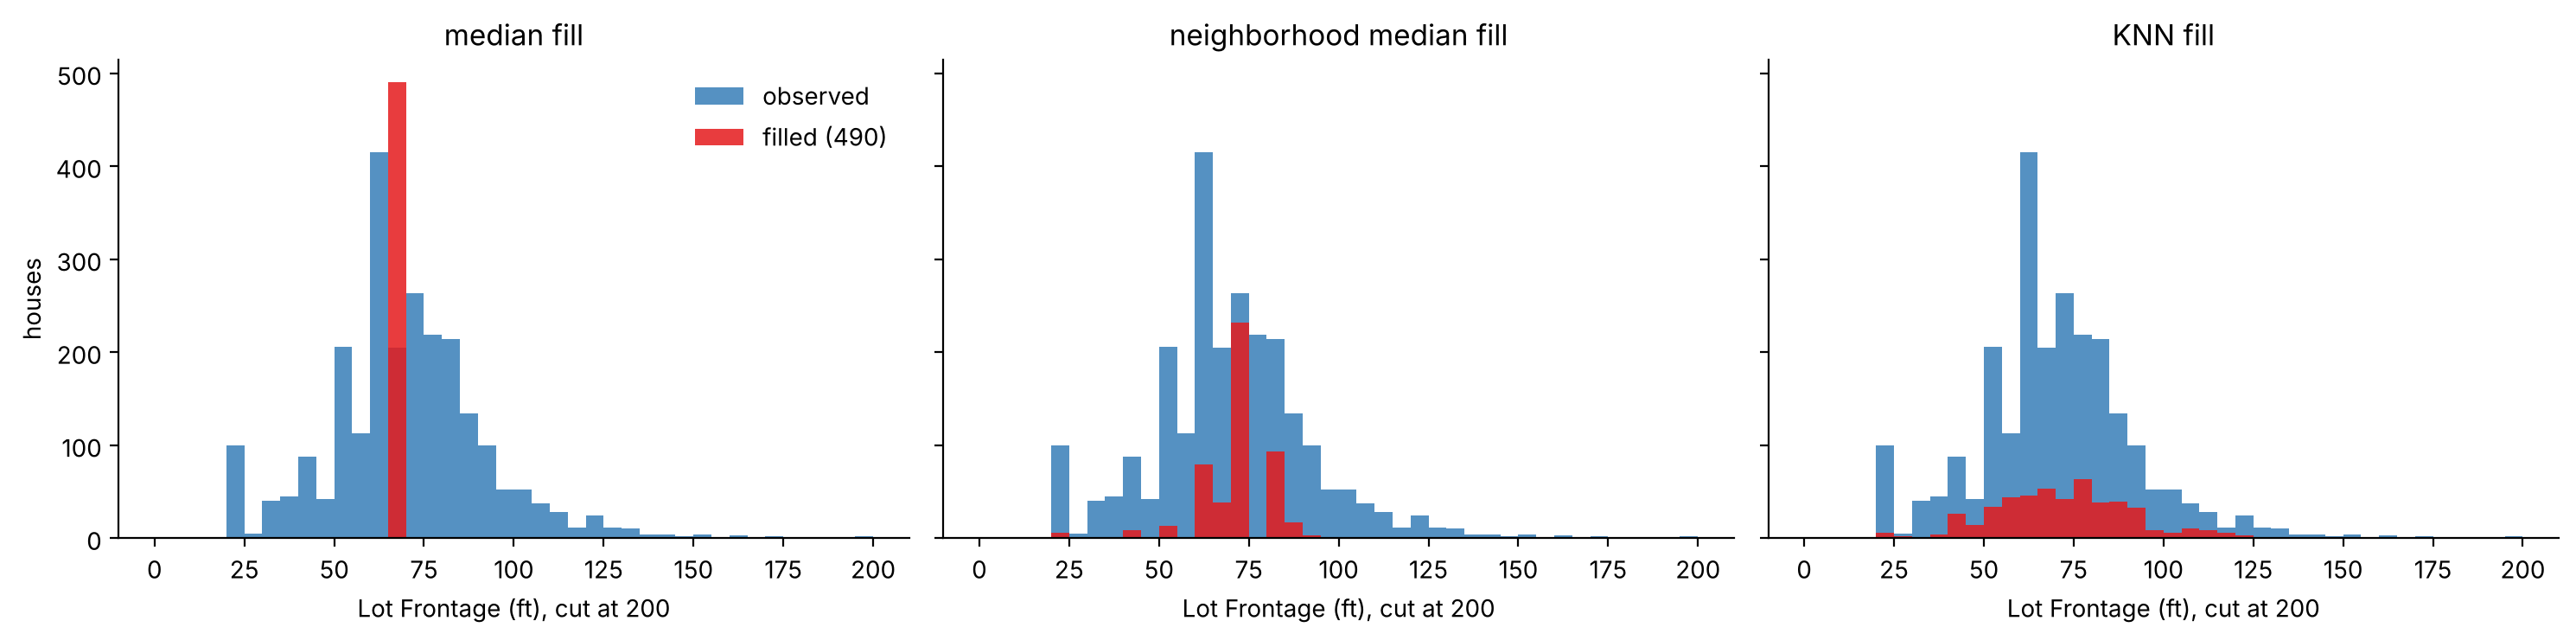

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
bins = np.arange(0, 205, 5)
for ax, (name, after) in zip(axes, filled.items()):
    ax.hist(before.dropna(), bins=bins, color="#377eb8", alpha=0.85, label="observed")
    ax.hist(after[missing], bins=bins, color="#e41a1c", alpha=0.85, label="filled (490)")
    ax.set_title(name + " fill")
    ax.set_xlabel("Lot Frontage (ft), cut at 200")
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylabel("houses")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.show()

## Part 7: leakage-safe evaluation
Same model, same folds. The three variants differ only in when the imputer learns.

In [17]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import Pipeline

NUMERIC_FEATURES = [
    "Lot Frontage", "Lot Area", "Overall Qual", "Overall Cond", "Year Built",
    "Gr Liv Area", "1st Flr SF", "Full Bath", "Half Bath", "Bedroom AbvGr",
    "TotRms AbvGrd", "Fireplaces", "Wood Deck SF", "Open Porch SF",
]
cv = KFold(n_splits=5, shuffle=True, random_state=5110)
y = np.log(df["SalePrice"])
X_with_key = df[NUMERIC_FEATURES + ["Lot Config"]]

In [18]:
# A: fill with the median Lot Frontage of the house's SalePrice quintile (uses the answer)
quintile = pd.qcut(df["SalePrice"], 5, labels=False)
print("fill value per price band:", df.groupby(quintile)["Lot Frontage"].median().to_dict())

X_A = df[NUMERIC_FEATURES].copy()
X_A["Lot Frontage"] = X_A["Lot Frontage"].fillna(
    X_A.groupby(quintile)["Lot Frontage"].transform("median"))

# B: fit the KNN imputer on all 2,930 rows first, then cross-validate
X_B = KNNFrontageImputer().fit_transform(X_with_key)

# C: imputer inside a Pipeline, refit on the training folds each time
pipe_C = Pipeline([("impute", KNNFrontageImputer()), ("model", LinearRegression())])

fill value per price band: {0: 60.0, 1: 65.0, 2: 70.0, 3: 70.0, 4: 83.0}


In [19]:
variants = {
    "A (SalePrice-quintile median, full table)": (LinearRegression(), X_A),
    "B (KNN fit on full table, then CV)": (LinearRegression(), X_B),
    "C (KNN inside Pipeline)": (pipe_C, X_with_key),
    "reference: Lot Frontage dropped": (LinearRegression(), df[NUMERIC_FEATURES[1:]]),
}

rmse = {}
for name, (model, X) in variants.items():
    scores = -cross_val_score(model, X, y, cv=cv, scoring="neg_root_mean_squared_error")
    rmse[name] = {"CV RMSE (log $)": scores.mean(), "fold sd": scores.std()}
pd.DataFrame(rmse).T.round(5)

,CV RMSE (log $),fold sd
"A (SalePrice-quintile median, full table)",0.16243,0.01369
"B (KNN fit on full table, then CV)",0.16231,0.01345
C (KNN inside Pipeline),0.16231,0.01341
reference: Lot Frontage dropped,0.16258,0.01248


In [20]:
a, b, c = [rmse[name]["CV RMSE (log $)"] for name in list(variants)[:3]]
print(f"A - C = {a - c:+.5f}")
print(f"B - C = {b - c:+.6f}")

# How strongly do the 490 filled values track price?
print()
print("corr(filled Lot Frontage, log SalePrice) on the 490 filled rows")
print("  A:", round(X_A["Lot Frontage"][missing].corr(y[missing]), 3))
print("  B and C:", round(X_B["Lot Frontage"][missing].corr(y[missing]), 3))
print("  real frontage, observed rows:", round(df["Lot Frontage"].corr(y), 3))

A - C = +0.00012
B - C = +0.000001

corr(filled Lot Frontage, log SalePrice) on the 490 filled rows
  A: 0.891
  B and C: 0.219
  real frontage, observed rows: 0.35


**Reading the result**

- C is the correct estimate: the imputer only ever learns from the training folds.
- A leaks the target. Its filled values correlate about 0.89 with price, because they were built from the price. It also can't be used on an unsold house.
- B leaks the test fold's features into the fill. Here the effect is tiny, because the imputer never sees the price and 80% of the houses give nearly the same fill as 100%.

The written answers for all eight parts are in `reports/report.md`.